# 06 — Thí nghiệm thành phần và tính khả thi

> Notebook trình bày, **không huấn luyện lại**. Mọi bảng và hình được tính từ file kết quả đã lưu trong `saved/`, chạy lại an toàn trên CPU. Log huấn luyện đã được rút gọn (bỏ thanh tiến độ, giữ mọi kết quả eval); bản đầy đủ nằm trong `ASR/notebooks/local` và `ASR/local/logs`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
S = next(p / 'saved' for p in [Path.cwd(), *Path.cwd().parents] if (p / 'saved/tables').is_dir())
T = S / 'tables'
def js(rel): return json.loads((S / rel).read_text(encoding='utf-8'))
def show_log(name): print((S / 'logs' / name).read_text(encoding='utf-8'))
def history(name): return js(f'runs/{name}_trainer_state.json')['log_history']
pd.set_option('display.precision', 2)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
C = {'Baseline 1': '#7E9C9B', 'Baseline 2': '#A9C2C0', 'V1': '#0F4E57', 'V2': '#1A6771', 'V-Final': '#FFB21A'}

## Thí nghiệm thành phần (ViMedCSS chia theo video)
Các run này đo tác dụng riêng của từng thành phần trước khi gộp vào V-Final. Chúng dùng ViMedCSS chia lại theo video (80/10/10,
seed 13, không trùng video giữa các tập), nên số **không so trực tiếp** với DEV chính thức ở các notebook trước.

In [2]:
show_log('thanh_phan_chia_theo_video_train.txt')

===== 20261024_154859_493188.log
[INIT] mode=train experiment=V3_phowhisper_small_lora_vsplit; importing PyTorch/ASR libraries...
{
  "python": "D:\\1.FPT_FALL26\\DPL - Deep Learning\\.venv-asr\\Scripts\\python.exe",
  "cuda": true,
  "versions": {
    "torch": "2.6.0+cu124",
    "transformers": "4.46.3",
    "peft": "0.13.2",
    "accelerate": "1.1.1",
    "datasets": "3.1.0"
  },
  …
}
[MODEL] Loading processor and weights; first use may download model files...
trainable params: 12,976,128 || all params: 254,711,040 || trainable%: 5.0945
[MODEL] Weights loaded.
[DATA] Loading TRAIN parquet and applying duration filters...
Exclude VIVOS/train: 1 rows listed in v3_train_exclude.json
Exclude FLEURS/train: 0 rows listed in v3_train_exclude.json
Exclude VietMed/train: 0 rows listed in v3_train_exclude.json
Exclude ViMedCSS_vsplit/train: 13 rows listed in v3_train_exclude.json
[DATA] TRAIN: 29913 clips. Loading DEV...
[DATA] DEV: 600 clips.
train=29913 dev=600 resume_from_checkpoint=None
[

In [3]:
show_log('thanh_phan_specaugment_train.txt')

===== 20261025_232509_318288.log
[INIT] mode=train experiment=V4_phowhisper_small_lora_vsplit_specaug; importing PyTorch/ASR libraries...
{
  "python": "D:\\1.FPT_FALL26\\DPL - Deep Learning\\.venv-asr\\Scripts\\python.exe",
  "cuda": true,
  "versions": {
    "torch": "2.6.0+cu124",
    "transformers": "4.46.3",
    "peft": "0.13.2",
    "accelerate": "1.1.1",
    "datasets": "3.1.0"
  },
  …
}
[MODEL] Loading processor and weights; first use may download model files...
trainable params: 12,976,128 || all params: 254,711,040 || trainable%: 5.0945
[MODEL] Weights loaded.
[DATA] Loading TRAIN parquet and applying duration filters...
Exclude VIVOS/train: 1 rows listed in v3_train_exclude.json
Exclude FLEURS/train: 0 rows listed in v3_train_exclude.json
Exclude VietMed/train: 0 rows listed in v3_train_exclude.json
Exclude ViMedCSS_vsplit/train: 13 rows listed in v3_train_exclude.json
[DATA] TRAIN: 29913 clips. Loading DEV...
[DATA] DEV: 600 clips.
train=29913 dev=600 resume_from_checkpoin

In [4]:
show_log('thanh_phan_medium_train.txt')

===== 20261028_130054_908352.log
[INIT] mode=train experiment=V5_phowhisper_medium_lora_vsplit_specaug; importing PyTorch/ASR libraries...
{
  "python": "D:\\1.FPT_FALL26\\DPL - Deep Learning\\.venv-asr\\Scripts\\python.exe",
  "cuda": true,
  "versions": {
    "torch": "2.6.0+cu124",
    "transformers": "4.46.3",
    "peft": "0.13.2",
    "accelerate": "1.1.1",
    "datasets": "3.1.0"
  },
  …
}
[MODEL] Loading processor and weights; first use may download model files...
trainable params: 34,603,008 || all params: 798,460,928 || trainable%: 4.3337
[MODEL] Weights loaded.
[DATA] Loading TRAIN parquet and applying duration filters...
Exclude VIVOS/train: 1 rows listed in v3_train_exclude.json
Exclude FLEURS/train: 0 rows listed in v3_train_exclude.json
Exclude VietMed/train: 0 rows listed in v3_train_exclude.json
Exclude ViMedCSS_vsplit/train: 13 rows listed in v3_train_exclude.json
[DATA] TRAIN: 29913 clips. Loading DEV...
[DATA] DEV: 600 clips.
train=29913 dev=600 resume_from_checkpoi

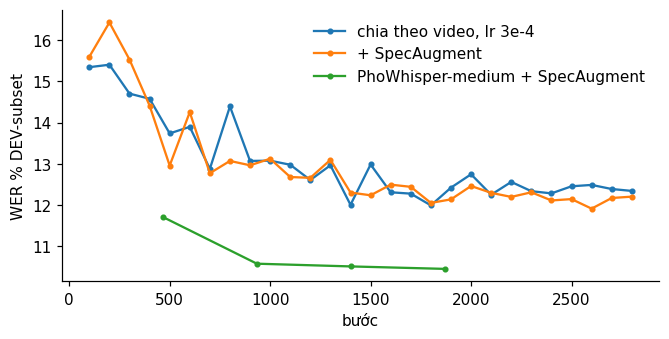

In [5]:
c = pd.read_csv(T / 'eval_curves.csv')
lab = {'V3': 'chia theo video, lr 3e-4', 'V4': '+ SpecAugment', 'V5': 'PhoWhisper-medium + SpecAugment'}
fig, ax = plt.subplots(figsize=(7, 3.2))
for k, l in lab.items():
    d = c[c.run == k]; ax.plot(d.step, d.eval_wer, marker='o', ms=3, label=l)
ax.set_xlabel('bước'); ax.set_ylabel('WER % DEV-subset'); ax.legend(frameon=False); plt.show()

In [6]:
d = pd.read_csv(T / 'ablation_dev_v3.csv').set_index('run')
lab = {'B0V': 'Baseline 1', 'V3': 'chia theo video', 'V3B': 'chia theo video, beam 5', 'V4': '+ SpecAugment', 'V4B': '+ SpecAugment, beam 5', 'V5': 'medium', 'V5B': 'medium, beam 5'}
d = d.loc[[k for k in lab if k in d.index], ['decode', 'wer', 'term_recall', 'wer_ViMedCSS', 'wer_VietMed', 'rtf']].rename(index=lab)
d

,decode,wer,term_recall,wer_ViMedCSS,wer_VietMed,rtf
run,,,,,,
Baseline 1,greedy,24.83,9.05,29.05,25.87,0.10
chia theo video,greedy,18.26,60.11,16.59,21.63,0.10
"chia theo video, beam 5",beam 5,17.44,64.11,15.84,20.64,0.14
+ SpecAugment,greedy,17.96,62.48,16.57,21.12,0.09
"+ SpecAugment, beam 5",beam 5,17.26,66.42,15.40,20.55,0.21
medium,greedy,15.67,69.73,13.41,19.25,0.18
"medium, beam 5",beam 5,15.33,72.53,12.72,19.08,0.32


In [7]:
w = d.wer
print(f"SpecAugment: {w['+ SpecAugment'] - w['chia theo video']:+.2f} điểm (greedy)")
print(f"Beam 5: {w['+ SpecAugment, beam 5'] - w['+ SpecAugment']:+.2f} điểm (cùng mô hình SpecAugment)")
print(f"Backbone medium (beam 5): {w['medium, beam 5'] - w['+ SpecAugment, beam 5']:+.2f} điểm")

SpecAugment: -0.30 điểm (greedy)
Beam 5: -0.71 điểm (cùng mô hình SpecAugment)
Backbone medium (beam 5): -1.92 điểm


## Tính khả thi: độ chính xác, tốc độ, kích thước

In [8]:
l = pd.read_csv(T / 'latency_size.csv').set_index('system')
l = l.rename(index={'V4 (small)': 'small + SpecAugment, greedy', 'V4B (small)': 'small + SpecAugment, beam 5', 'V5 (medium)': 'medium, greedy', 'V5B (medium)': 'medium, beam 5'})
vf = js('metrics/VFinal_test_beam5.json')
l.loc['V-Final (A100, beam 5)'] = {'params_M': 1550, 'adapter_MB': js('runs/VFinal_adapter.json')['adapter_MB'], 'dev_wer': 100 * js('metrics/VFinal_dev_beam5.json')['overall']['wer'], 'rtf': vf['rtf_decode_only']}
l = l[['params_M', 'adapter_MB', 'dev_wer', 'rtf', 'eval_gpu_gb', 'train_gpu_gb']].astype({'params_M': int})
l['rtf'] = l['rtf'].map('{:.3f}'.format)
l

,params_M,adapter_MB,dev_wer,rtf,eval_gpu_gb,train_gpu_gb
system,,,,,,
"small + SpecAugment, beam 5",244,51.96,17.26,0.208,2.09,4.06
"small + SpecAugment, greedy",244,51.96,17.96,0.088,1.79,4.06
"medium, greedy",769,138.52,15.67,0.177,3.01,4.29
"medium, beam 5",769,138.52,15.33,0.321,3.78,4.29
"V-Final (A100, beam 5)",1550,230.83,15.07,0.037,NaN,NaN


- RTF = thời gian giải mã / thời lượng audio. Các dòng small/medium đo trên RTX 4050 6 GB, V-Final đo trên A100 (batch 16), nên không so trực tiếp.
- `dev_wer` của small/medium là DEV chia theo video; của V-Final là DEV chính thức.
- Chưa đo VRAM và tốc độ của V-Final trên GPU 6 GB.

**Kết luận: CÓ khả thi, có điều kiện.** Dùng làm bản nháp có người soát (còn sót khoảng 2/10 đến 3/10 thuật ngữ trên TEST);
máy 6 GB dùng bản medium, V-Final khi có GPU từ 8 GB và đã đo lại.